In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import random
import cv2
import sklearn
from PIL import Image
from pathlib import Path
from fastai.vision.all import *
from fastai.callback import *
from fastai.metrics import error_rate
from fastai.callback.tracker import EarlyStoppingCallback
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from pathlib import Path
import os


import warnings
warnings.filterwarnings ('ignore')

In [2]:
dataset_dir = "/kaggle/input/melanoma"

In [3]:
dataset_dir = Path(dataset_dir)

In [4]:
files = list(dataset_dir.glob("**/*.jpg"))
print(f'Total Images = {len(files)}')

Total Images = 10605


In [5]:


train = '/kaggle/input/melanoma/melanoma_cancer_dataset/train'  


LABELS = os.listdir(train)
LABELS = sorted(LABELS)


for label in LABELS:import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader


transform = transforms.Compose([
    transforms.Resize((224, 224)), 
    
   
    transforms.RandomHorizontalFlip(),  
    transforms.RandomRotation(10),     
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2), 
    
  
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalization
])


train_dataset = datasets.ImageFolder(root='/kaggle/input/melanoma/melanoma_cancer_dataset/train', transform=transform)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)


for images, labels in train_loader:
    print(f"Batch of images shape: {images.shape}")
    print(f"Batch of labels: {labels}")
    break  # Just showing the first batch with augmentation

  
    label_dir = Path(os.path.join(dataset_dir, label))
    
    
    total_images_label = list(label_dir.glob("*.jpg"))
    
    print(f'* {label}: {len(total_images_label)} images\n')


Batch of images shape: torch.Size([32, 3, 224, 224])
Batch of labels: tensor([1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1,
        0, 0, 0, 1, 0, 1, 0, 0])


In [6]:
test_data = Path ("/kaggle/input/melanoma/melanoma_cancer_dataset/test")

In [7]:
dls = ImageDataLoaders.from_folder(dataset_dir, train='train', valid_pct=0.2, 
                                          item_tfms=Resize(460), 
                                          batch_tfms=[*aug_transforms(size=224), Normalize.from_stats(*imagenet_stats)])

In [8]:
len(dls.train_ds)

8484

In [9]:
len(dls.valid_ds)

2121

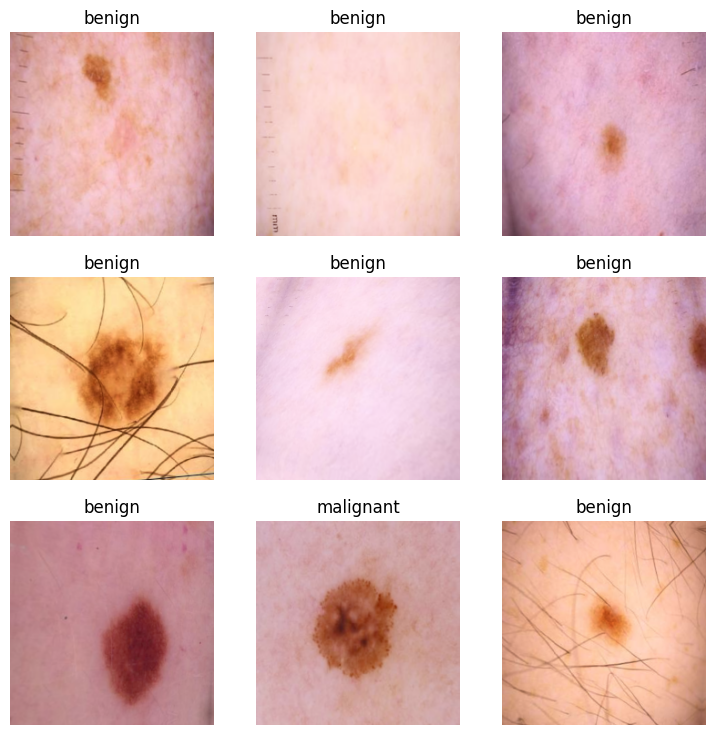

In [10]:
dls.show_batch()

In [11]:
learn = vision_learner(dls, resnet34, metrics=accuracy)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth
100%|██████████| 83.3M/83.3M [00:00<00:00, 89.5MB/s]


In [12]:
learn.model_dir = "/kaggle/working/"

In [13]:
learn.summary()

Sequential (Input shape: 64 x 3 x 224 x 224)
Layer (type)         Output Shape         Param #    Trainable 
                     64 x 64 x 112 x 112 
Conv2d                                    9408       False     
BatchNorm2d                               128        True      
ReLU                                                           
____________________________________________________________________________
                     64 x 64 x 56 x 56   
MaxPool2d                                                      
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
ReLU                                                           
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
ReLU                      

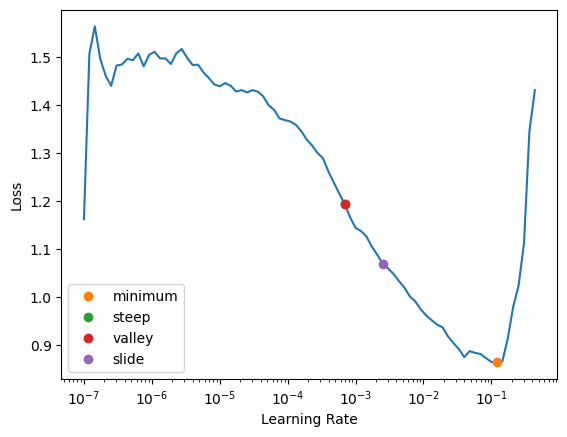

In [14]:
suggest_funcs = (minimum, steep, valley, slide)

lrs = learn.lr_find(suggest_funcs=suggest_funcs)

In [15]:
lrs

SuggestedLRs(minimum=0.012022644281387329, steep=0.0006918309954926372, valley=0.0006918309954926372, slide=0.002511886414140463)

In [16]:
learn.fit_one_cycle(3, lr_max=slice(lrs.valley, lrs.slide))

epoch,train_loss,valid_loss,accuracy,time
0,0.394388,0.246743,0.903819,28:49
1,0.260358,0.182395,0.930222,29:22
2,0.217732,0.171722,0.933050,25:12


<Axes: title={'center': 'learning curve'}, xlabel='steps', ylabel='loss'>

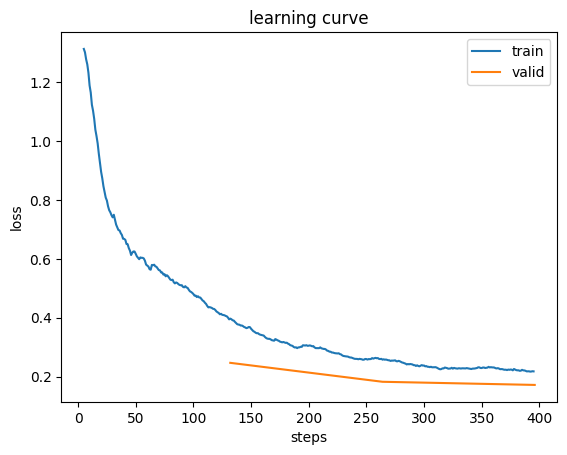

In [17]:
learn.recorder.plot_loss()

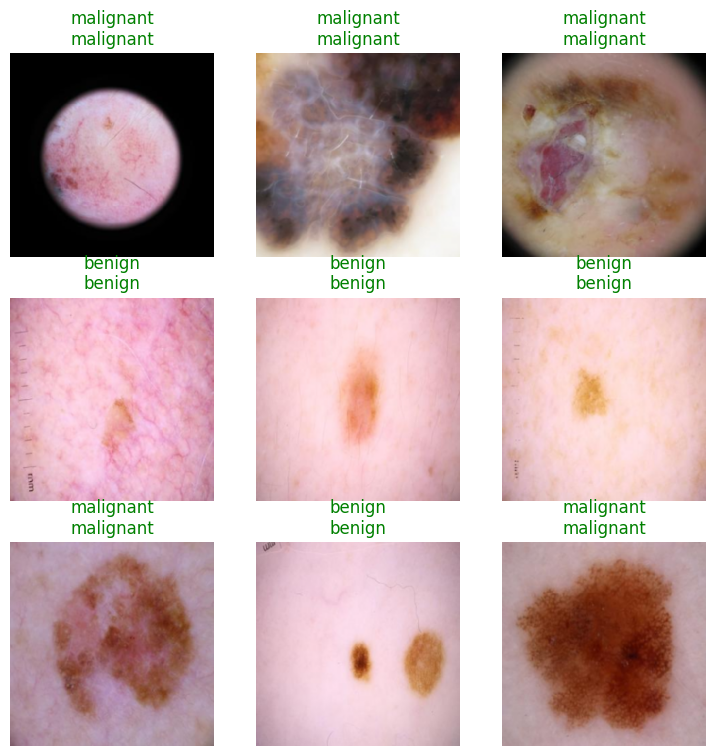

In [18]:
learn.show_results()

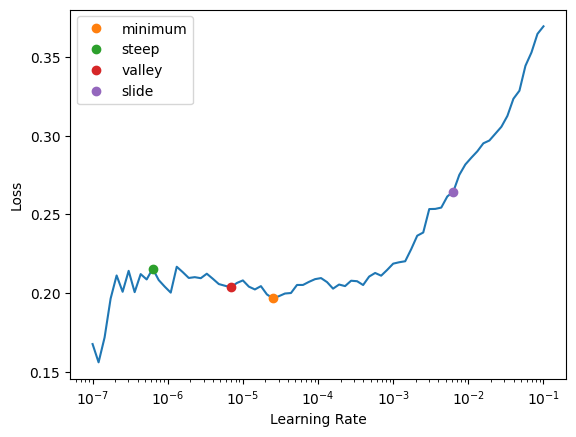

In [19]:
learn.unfreeze()
lrs = learn.lr_find(suggest_funcs=(minimum, steep, valley, slide))

In [20]:
lrs

SuggestedLRs(minimum=2.511886486900039e-06, steep=6.309573450380412e-07, valley=6.918309736647643e-06, slide=0.0063095735386013985)

In [21]:
learn.fit_one_cycle(10, lr_max=slice(lrs.valley, lrs.slide))

epoch,train_loss,valid_loss,accuracy,time
0,0.209652,0.175244,0.932579,39:32
1,0.219707,0.184686,0.929279,37:48
2,0.200538,0.146949,0.944366,35:56
3,0.183839,0.165571,0.939651,35:48
4,0.172140,0.156141,0.938708,35:58
5,0.129909,0.142256,0.943894,36:20
6,0.109238,0.149602,0.940123,39:11
7,0.081844,0.145737,0.950024,39:08
8,0.050724,0.162771,0.951438,51:19
9,0.038246,0.169855,0.951909,41:44


<Axes: title={'center': 'learning curve'}, xlabel='steps', ylabel='loss'>

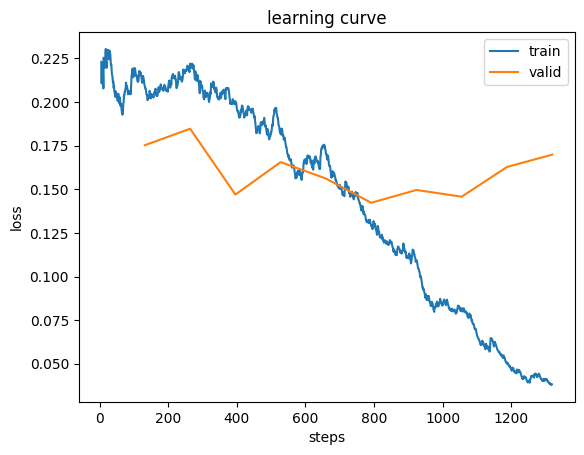

In [22]:
learn.recorder.plot_loss()

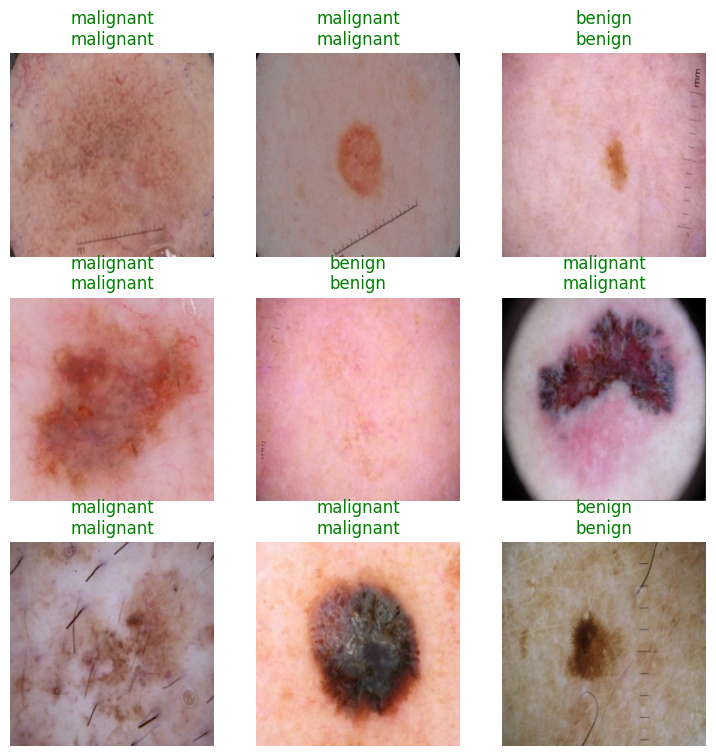

In [23]:
learn.show_results()

In [24]:
test_data = '/kaggle/input/melanoma/melanoma_cancer_dataset/test' 

test_dl = learn.dls.test_dl(get_image_files(test_data), with_labels=True)

preds, targets = learn.get_preds(dl=test_dl)

predicted_classes = torch.argmax(preds, dim=1)

In [25]:
class_report = classification_report(targets, predicted_classes, target_names=learn.dls.vocab)
print(class_report)

              precision    recall  f1-score   support

      benign       0.97      0.99      0.98       500
   malignant       0.99      0.97      0.98       500

    accuracy                           0.98      1000
   macro avg       0.98      0.98      0.98      1000
weighted avg       0.98      0.98      0.98      1000



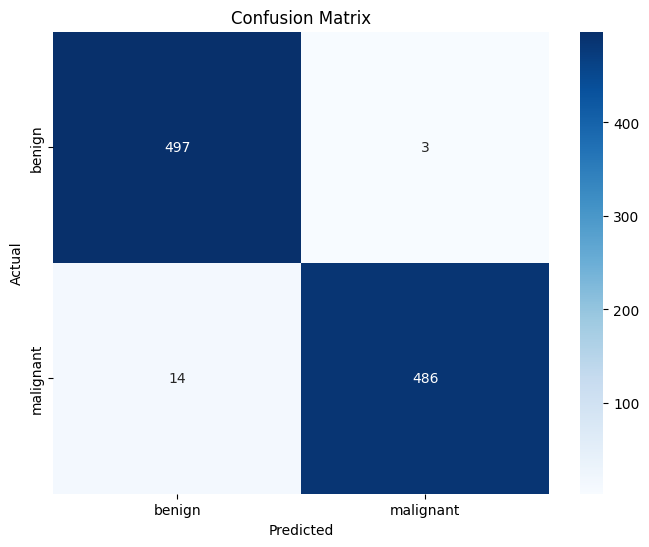

In [26]:
cm = confusion_matrix(targets, predicted_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=learn.dls.vocab, yticklabels=learn.dls.vocab)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

**K-fold cross validation**

In [34]:
from sklearn.model_selection import KFold
all_images = get_image_files(train)

In [35]:
n_splits = 3
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
fold_accuracies = []
fold_roc_aucs = []


In [ ]:
for fold, (train_idx, val_idx) in enumerate(kf.split(all_images)):
    print(f'Fold {fold + 1}/{n_splits}')
    train_files = [all_images[i] for i in train_idx]
    val_files = [all_images[i] for i in val_idx]
    train_dl = learn.dls.test_dl(train_files, with_labels=True)
    val_dl = learn.dls.test_dl(val_files, with_labels=True)
    learn.fit_one_cycle(1, lr_max=slice(lrs.valley, lrs.slide))

Fold 1/3


epoch,train_loss,valid_loss,accuracy,time


In [ ]:
preds, targets = learn.get_preds(dl=val_dl)
    predicted_classes = torch.argmax(preds, dim=1)

In [ ]:
accuracy = (predicted_classes == targets).float().mean().item()
    fold_accuracies.append(accuracy)

In [ ]:
  from sklearn.metrics import roc_auc_score
    roc_auc = roc_auc_score(targets.cpu(), preds[:,1].cpu())  # If binary classification
    fold_roc_aucs.append(roc_auc)

In [ ]:
print(f'Average Accuracy: {np.mean(fold_accuracies)}')
print(f'Average ROC-AUC: {np.mean(fold_roc_aucs)}')

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Placeholder for all metrics
fold_metrics = []

for fold, (train_idx, val_idx) in enumerate(kf.split(all_images)):
    print(f'Fold {fold + 1}/{n_splits}')
    
    train_files = [all_images[i] for i in train_idx]
    val_files = [all_images[i] for i in val_idx]
    
    train_dl = learn.dls.test_dl(train_files, with_labels=True)
    val_dl = learn.dls.test_dl(val_files, with_labels=True)
    
    # Track training metrics
    learn.fit_one_cycle(3, lr_max=slice(lrs.valley, lrs.slide))
    
    preds, targets = learn.get_preds(dl=val_dl)
    predicted_classes = torch.argmax(preds, dim=1)
    
    # Calculate Metrics
    accuracy = (predicted_classes == targets).float().mean().item()
    roc_auc = roc_auc_score(targets.cpu(), preds[:, 1].cpu())  # Assuming binary classification
    
    fpr, tpr, _ = roc_curve(targets.cpu(), preds[:, 1].cpu())
    
    fold_metrics.append({
        "fold": fold + 1,
        "accuracy": accuracy,
        "roc_auc": roc_auc,
        "fpr": fpr,
        "tpr": tpr,
    })

# Stepwise K-Fold Accuracy
accuracies = [metric["accuracy"] for metric in fold_metrics]
roc_aucs = [metric["roc_auc"] for metric in fold_metrics]

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(accuracies) + 1), accuracies, marker='o', label='Accuracy')
plt.plot(range(1, len(roc_aucs) + 1), roc_aucs, marker='o', label='ROC-AUC')
plt.xlabel("Fold")
plt.ylabel("Metric Value")
plt.title("Stepwise K-Fold Metrics")
plt.legend()
plt.show()

# ROC Curve for Each Fold
plt.figure(figsize=(10, 7))
for metric in fold_metrics:
    plt.plot(metric["fpr"], metric["tpr"], label=f"Fold {metric['fold']} (AUC = {metric['roc_auc']:.4f})")
    
plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Each Fold")
plt.legend()
plt.show()

# Training and Validation Loss Plot
train_losses = learn.recorder.losses
valid_losses = learn.recorder.values
epochs = list(range(1, len(train_losses) + 1))

plt.figure(figsize=(10, 5))
plt.plot(epochs, train_losses, label='Training Loss')
plt.plot(epochs, valid_losses, label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Over Epochs")
plt.legend()
plt.show()
